In [27]:
import pandas as pd

# ---- 1. load -------------------------------------------------------------
train = pd.read_parquet('../data/processed/features_train.parquet')
test  = pd.read_parquet('../data/processed/features_test.parquet')

# slice 4 fixed the row order, but a new notebook does not get to assume it
assert train['issue_d'].is_monotonic_increasing, "train is not in time order"
assert test['issue_d'].is_monotonic_increasing,  "test is not in time order"

print("train:", train.shape, train['issue_d'].min().date(), "->", train['issue_d'].max().date())
print("test: ", test.shape,  test['issue_d'].min().date(),  "->", test['issue_d'].max().date())
print("80% of train falls at:", train['issue_d'].quantile(0.8).date())

train: (20902, 76) 2013-01-01 -> 2016-08-01
test:  (5378, 76) 2016-09-01 -> 2017-12-01
80% of train falls at: 2016-01-01


In [28]:
# ---- 2. carve validation out of train, by date --------------------------
SPLIT_DATE = pd.Timestamp('2016-01-01')   # the month boundary nearest the 80% mark

# .copy() so later edits touch these frames, not a view of train
train_inner = train[train['issue_d'] <  SPLIT_DATE].copy()
valid       = train[train['issue_d'] >= SPLIT_DATE].copy()

# ---- 3. prove the split is clean ----------------------------------------
assert len(train_inner) + len(valid) == len(train), "rows lost or duplicated"
assert train_inner['issue_d'].max() < valid['issue_d'].min(), "the sets overlap in time"
assert train_inner['issue_d'].is_monotonic_increasing
assert valid['issue_d'].is_monotonic_increasing

summary = pd.DataFrame([
    {"set": "train_inner", "rows": len(train_inner),
     "from": train_inner['issue_d'].min().date(), "to": train_inner['issue_d'].max().date(),
     "bad_rate": train_inner['target'].mean()},
    {"set": "valid",       "rows": len(valid),
     "from": valid['issue_d'].min().date(),       "to": valid['issue_d'].max().date(),
     "bad_rate": valid['target'].mean()},
    {"set": "test",        "rows": len(test),
     "from": test['issue_d'].min().date(),        "to": test['issue_d'].max().date(),
     "bad_rate": test['target'].mean()},
])
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nvalid is {len(valid) / len(train):.1%} of the original train")

        set  rows       from         to  bad_rate
train_inner 16134 2013-01-01 2015-12-01    0.1890
      valid  4768 2016-01-01 2016-08-01    0.2391
       test  5378 2016-09-01 2017-12-01    0.2365

valid is 22.8% of the original train


In [29]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

NON_FEATURES = ['target', 'issue_d', 'earliest_cr_line', 'zip_code', 'addr_state']

X_train_inner = train_inner.drop(columns=NON_FEATURES)
y_train_inner = train_inner['target']

X_valid = valid.drop(columns=NON_FEATURES)
y_valid = valid['target']

X_test  = test.drop(columns=NON_FEATURES)
y_test  = test['target']

# the scaler works by position, so all three frames must line up exactly
assert list(X_train_inner.columns) == list(X_valid.columns), "valid columns differ"
assert list(X_train_inner.columns) == list(X_test.columns),  "test columns differ"

print("train_inner:", X_train_inner.shape)
print("valid:      ", X_valid.shape)
print("test:       ", X_test.shape)

train_inner: (16134, 71)
valid:       (4768, 71)
test:        (5378, 71)


In [30]:
scaler_inner = StandardScaler()
scaler_inner.fit(X_train_inner)       # means and stds learned here, and nowhere else

def rescale(X):
    """apply train_inner's numbers, and keep the column names"""
    return pd.DataFrame(scaler_inner.transform(X), columns=X.columns, index=X.index)

X_train_inner_s = rescale(X_train_inner)
X_valid_s       = rescale(X_valid)
X_test_s        = rescale(X_test)

for name, Xs in [("train_inner", X_train_inner_s),
                 ("valid",       X_valid_s),
                 ("test",        X_test_s)]:
    print(f"{name:12} mean {Xs.mean().mean():+.4f}   std {Xs.std().mean():.4f}")

train_inner  mean -0.0000   std 1.0000
valid        mean -0.0002   std 1.0918
test         mean +0.0116   std 1.1678


In [31]:
model_inner = LogisticRegression(
    l1_ratio=1.0,        # pure L1 - the setting slice 4 verified
    solver="liblinear",
    C=0.05,              # chosen in slice 4, deliberately NOT re-tuned here
    max_iter=2000,
    random_state=42,
)
model_inner.fit(X_train_inner_s, y_train_inner)

p_train_inner = model_inner.predict_proba(X_train_inner_s)[:, 1]
p_valid       = model_inner.predict_proba(X_valid_s)[:, 1]
p_test        = model_inner.predict_proba(X_test_s)[:, 1]

In [32]:
AUC_SLICE4 = 0.6973      # the model trained on all of train

auc_train_inner = roc_auc_score(y_train_inner, p_train_inner)
auc_valid       = roc_auc_score(y_valid, p_valid)
auc_test        = roc_auc_score(y_test,  p_test)

n_kept = (model_inner.coef_[0] != 0).sum()

print(f"train_inner AUC: {auc_train_inner:.4f}   (in-sample - the model has seen these)")
print(f"valid       AUC: {auc_valid:.4f}   (unseen)")
print(f"test        AUC: {auc_test:.4f}   (unseen)")
print()
print(f"features kept: {n_kept} of {X_train_inner_s.shape[1]}   (slice 4 kept 47)")
print(f"slice 4 test AUC {AUC_SLICE4:.4f}  ->  now {auc_test:.4f}   "
      f"change {auc_test - AUC_SLICE4:+.4f}")

train_inner AUC: 0.7176   (in-sample - the model has seen these)
valid       AUC: 0.7019   (unseen)
test        AUC: 0.6908   (unseen)

features kept: 47 of 71   (slice 4 kept 47)
slice 4 test AUC 0.6973  ->  now 0.6908   change -0.0065


In [33]:
import joblib

b = joblib.load('../models/baseline_logreg.joblib')

old_coefs = pd.Series(b['model'].coef_[0], index=b['columns'])
new_coefs = pd.Series(model_inner.coef_[0], index=X_train_inner_s.columns)

old_kept = set(old_coefs[old_coefs != 0].index)
new_kept = set(new_coefs[new_coefs != 0].index)

print(f"slice 4 kept {len(old_kept)}, now {len(new_kept)}, in both {len(old_kept & new_kept)}")
print("dropped since slice 4:", sorted(old_kept - new_kept))
print("newly kept:           ", sorted(new_kept - old_kept))

slice 4 kept 47, now 47, in both 39
dropped since slice 4: ['bc_util', 'mort_acc', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_bc_sats', 'num_op_rev_tl', 'pub_rec_bankruptcies', 'total_rev_hi_lim']
newly kept:            ['application_type_Joint App', 'chargeoff_within_12_mths', 'emp_length', 'mo_sin_old_il_acct', 'num_tl_120dpd_2m', 'num_tl_90g_dpd_24m', 'open_to_total_acc', 'tax_liens']


In [34]:
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_curve

ap_valid = average_precision_score(y_valid, p_valid)
ap_test  = average_precision_score(y_test,  p_test)

floor_valid = y_valid.mean()
floor_test  = y_test.mean()

print(f"valid  AP {ap_valid:.4f}   no-skill floor {floor_valid:.4f}   "
      f"lift {ap_valid / floor_valid:.2f}x")
print(f"test   AP {ap_test:.4f}   no-skill floor {floor_test:.4f}   "
      f"lift {ap_test / floor_test:.2f}x")

valid  AP 0.4151   no-skill floor 0.2391   lift 1.74x
test   AP 0.3918   no-skill floor 0.2365   lift 1.66x


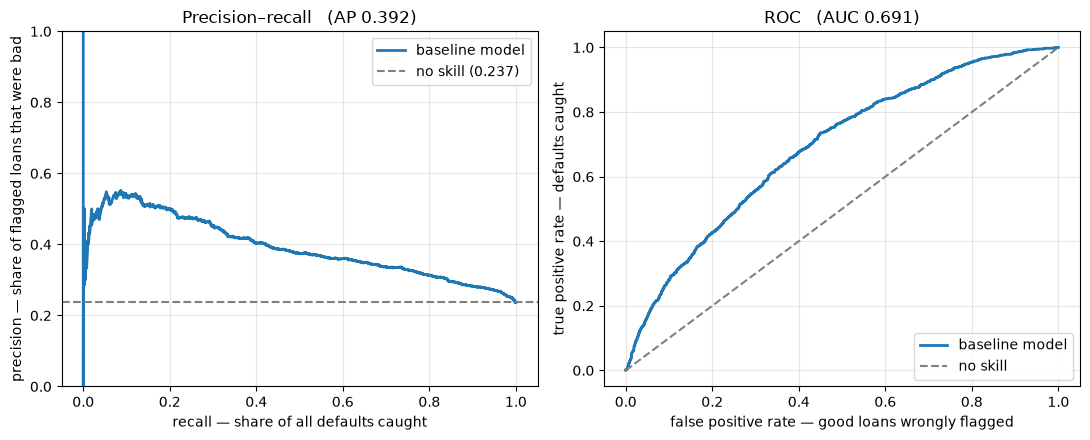

In [35]:
# ---- the curves ---------------------------------------------------------
prec, rec, pr_thresholds = precision_recall_curve(y_test, p_test)
fpr,  tpr, roc_thresholds = roc_curve(y_test, p_test)

# ---- the figure ---------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.plot(rec, prec, linewidth=2, label="baseline model")
ax.axhline(floor_test, linestyle="--", color="gray", linewidth=1.5,
           label=f"no skill ({floor_test:.3f})")
ax.set_xlabel("recall — share of all defaults caught")
ax.set_ylabel("precision — share of flagged loans that were bad")
ax.set_title(f"Precision–recall   (AP {ap_test:.3f})")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(fpr, tpr, linewidth=2, label="baseline model")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.5, label="no skill")
ax.set_xlabel("false positive rate — good loans wrongly flagged")
ax.set_ylabel("true positive rate — defaults caught")
ax.set_title(f"ROC   (AUC {auc_test:.3f})")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

fig.tight_layout()

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)
fig.savefig(FIG_DIR / "slice05_pr_and_roc.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
# drop the appended end point so these line up with the thresholds array
rec_t  = rec[:-1]
prec_t = prec[:-1]

print("recall   precision   lift   threshold")
for target in [0.10, 0.20, 0.30, 0.50, 0.75]:
    i = np.argmin(np.abs(rec_t - target))        # closest point on the curve
    print(f"{rec_t[i]:.2f}     {prec_t[i]:.3f}      "
          f"{prec_t[i] / floor_test:.2f}x   {pr_thresholds[i]:.3f}")

recall   precision   lift   threshold
0.10     0.531      2.25x   0.447
0.20     0.500      2.11x   0.361
0.30     0.453      1.92x   0.297
0.50     0.375      1.58x   0.208
0.75     0.329      1.39x   0.142


In [37]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

# ---- step 0: raw scores - log-odds, before the sigmoid ------------------
s_valid = model_inner.decision_function(X_valid_s)
s_test  = model_inner.decision_function(X_test_s)

print(f"score range valid: {s_valid.min():+.3f} to {s_valid.max():+.3f}")
print(f"score range test:  {s_test.min():+.3f} to {s_test.max():+.3f}")

# ---- steps 1-2: sigmoid (Platt), fitted on valid ------------------------
platt = LogisticRegression()
platt.fit(s_valid.reshape(-1, 1), y_valid)        # one input column

p_test_sigmoid = platt.predict_proba(s_test.reshape(-1, 1))[:, 1]

print(f"\nPlatt learned:  slope {platt.coef_[0][0]:+.4f}   "
      f"shift {platt.intercept_[0]:+.4f}")

# ---- steps 3-4: isotonic, fitted on valid -------------------------------
iso = IsotonicRegression(out_of_bounds="clip")
iso.fit(p_valid, y_valid)                         # flat input, NOT a column

p_test_iso = iso.predict(p_test)

print(f"isotonic: {len(np.unique(p_test_iso))} distinct values out, "
      f"{len(np.unique(p_test))} in   "
      f"({(p_test_iso == 0).sum()} exact 0s, {(p_test_iso == 1).sum()} exact 1s)")

# ---- step 5: the comparison table ---------------------------------------
VERSIONS = [
    ("uncalibrated", p_test),
    ("sigmoid",      p_test_sigmoid),
    ("isotonic",     p_test_iso),
]

rows = []
for name, probs in VERSIONS:
    rows.append({
        "version":        name,
        "brier":          brier_score_loss(y_test, probs),
        "log_loss":       log_loss(y_test, probs),
        "auc":            roc_auc_score(y_test, probs),
        "mean_predicted": probs.mean(),
        "actual":         y_test.mean(),
    })

compare = pd.DataFrame(rows)
compare["lean"] = compare["mean_predicted"] - compare["actual"]

print()
print(compare.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

# ---- step 6: a monotone map cannot reorder anything ---------------------
auc_uncal   = roc_auc_score(y_test, p_test)
auc_sigmoid = roc_auc_score(y_test, p_test_sigmoid)

assert np.isclose(auc_uncal, auc_sigmoid), \
    "the sigmoid changed the ranking - scores and labels are mismatched somewhere"
print("\nAUC unchanged by the sigmoid, as it must be")


# ---- step 7: the ten-bin calibration tables -----------------------------
def calibration_table(probs, y, n_bins=10):
    """mean predicted vs actual, in equal-sized bins"""
    d = pd.DataFrame({
        "p":   probs,
        "y":   y.values,          # .values -> match by position, not by index label
        "bin": pd.qcut(probs, n_bins, labels=False, duplicates="drop"),
    })
    out = d.groupby("bin").agg(
        n         = ("y", "size"),
        predicted = ("p", "mean"),
        actual    = ("y", "mean"),
    )
    out["gap"] = out["predicted"] - out["actual"]
    return out


for name, probs in VERSIONS:
    t = calibration_table(probs, y_test)
    print(f"\n--- {name} ---")
    print(t.to_string(float_format=lambda v: f"{v:.4f}"))
    print(f"bins: {len(t)}   worst gap: {t['gap'].abs().max():.4f}   "
          f"mean |gap|: {t['gap'].abs().mean():.4f}")

score range valid: -4.483 to +3.189
score range test:  -4.640 to +33.368

Platt learned:  slope +0.9475   shift +0.2898
isotonic: 75 distinct values out, 5378 in   (8 exact 0s, 6 exact 1s)

     version  brier  log_loss    auc  mean_predicted  actual    lean
uncalibrated 0.1698    0.5232 0.6908          0.1855  0.2365 -0.0511
     sigmoid 0.1668    0.5131 0.6908          0.2394  0.2365  0.0029
    isotonic 0.1664    0.5250 0.6897          0.2381  0.2365  0.0016

AUC unchanged by the sigmoid, as it must be

--- uncalibrated ---
       n  predicted  actual     gap
bin                                
0    538     0.0475  0.0539 -0.0064
1    538     0.0768  0.1004 -0.0236
2    538     0.0984  0.1654 -0.0671
3    537     0.1182  0.1601 -0.0420
4    538     0.1397  0.2063 -0.0666
5    538     0.1651  0.2398 -0.0747
6    537     0.1961  0.2998 -0.1037
7    538     0.2385  0.3011 -0.0626
8    538     0.3053  0.3457 -0.0404
9    538     0.4689  0.4926 -0.0237
bins: 10   worst gap: 0.1037   mean

In [38]:
# ================= the +33 score: where did it come from? =================

# ---- 1. find it ----------------------------------------------------------
i = int(np.argmax(s_test))

print(f"row position:  {i}")
print(f"score:         {s_test[i]:.3f}      (valid's highest was {s_valid.max():.3f})")
print(f"probability:   {p_test[i]:.12f}")
print(f"actual outcome: {y_test.iloc[i]}   (1 = defaulted)")
print(f"issued:        {test['issue_d'].iloc[i].date()}")


# ---- 2. each feature's contribution to that score ------------------------
row_scaled = X_test_s.iloc[i]                                  # 71 scaled values
weights    = pd.Series(model_inner.coef_[0], index=X_test_s.columns)

contrib = (row_scaled * weights).sort_values(key=abs, ascending=False)

# the score is just the sum of all contributions plus the intercept -
# if this check fails, something is misaligned
rebuilt = contrib.sum() + model_inner.intercept_[0]
print(f"\nrebuilt score: {rebuilt:.3f}   (must match {s_test[i]:.3f})")
assert np.isclose(rebuilt, s_test[i]), "contributions do not rebuild the score"

print("\n--- top 8 contributions ---")
print(contrib.head(8).to_string(float_format=lambda v: f"{v:+.4f}"))


# ---- 3. the raw numbers behind the biggest ones --------------------------
top_names = contrib.head(5).index.tolist()

detail = pd.DataFrame({
    "weight":       weights[top_names],
    "scaled":       row_scaled[top_names],
    "contribution": contrib[top_names],
    "raw_value":    X_test.iloc[i][top_names],
    "train_min":    X_train_inner[top_names].min(),
    "train_p99":    X_train_inner[top_names].quantile(0.99),
    "train_max":    X_train_inner[top_names].max(),
})

print("\n--- raw values vs what training ever saw ---")
print(detail.to_string(float_format=lambda v: f"{v:,.3f}"))


# ---- 4. one freak row, or a pattern? -------------------------------------
beyond = s_test > s_valid.max()

print(f"\ntest rows scoring above valid's maximum ({s_valid.max():.3f}): "
      f"{beyond.sum()} of {len(s_test)}")

if beyond.sum() > 0:
    print(f"  their scores:     {np.sort(s_test[beyond])[::-1][:20].round(2)}")
    print(f"  actually defaulted: {int(y_test.values[beyond].sum())} of {beyond.sum()}")

for cut in [0.9, 0.99, 0.999]:
    print(f"  predicted > {cut}: {(p_test > cut).sum()} loans")


# ---- 5. which features reach furthest outside the training range? --------
test_reach  = X_test_s.abs().max().sort_values(ascending=False)
train_reach = X_train_inner_s.abs().max()

reach = pd.DataFrame({
    "test_max_abs_scaled":  test_reach.head(10),
    "train_max_abs_scaled": train_reach[test_reach.head(10).index],
})
reach["ratio"] = reach["test_max_abs_scaled"] / reach["train_max_abs_scaled"]

print("\n--- features whose test values sit furthest from the training mean ---")
print(reach.to_string(float_format=lambda v: f"{v:,.1f}"))

row position:  3240
score:         33.368      (valid's highest was 3.189)
probability:   1.000000000000
actual outcome: 0   (1 = defaulted)
issued:        2017-05-01

rebuilt score: 33.368   (must match 33.368)

--- top 8 contributions ---
loan_to_income               +34.5077
term                          +0.7274
application_type_Joint App    +0.2839
fico                          -0.2105
acc_open_past_24mths          -0.1785
num_rev_tl_bal_gt_0           -0.1049
total_acc                     +0.0988
home_ownership_RENT           -0.0856

--- raw values vs what training ever saw ---
                            weight  scaled  contribution  raw_value  train_min  train_p99  train_max
loan_to_income               0.200 172.751        34.508     19.500      0.006      0.479      1.782
term                         0.437   1.664         0.727     60.000     36.000     60.000     60.000
application_type_Joint App   0.007  40.155         0.284      1.000      0.000      0.000      1.000
fico 

In [39]:
# ============ SENSITIVITY CHECK - not the headline numbers ==============

CAP = X_train_inner['loan_to_income'].max()
print(f"training's largest loan_to_income: {CAP:.3f}")

# ---- how much log loss comes from that single row? ----------------------
eps = 1e-15
pc  = np.clip(p_test_sigmoid, eps, 1 - eps)
per_row = -(y_test.values * np.log(pc) + (1 - y_test.values) * np.log(1 - pc))

print(f"\ntotal log loss: {per_row.mean():.4f}")
print(f"row {i} alone contributes {per_row[i] / len(y_test):.4f} of it "
      f"({per_row[i] / per_row.sum():.1%} of the total, from 1 of {len(y_test)} rows)")

# ---- A. drop rows beyond anything valid ever scored ---------------------
keep = s_test <= s_valid.max()
print(f"\nrows inside valid's score range: {keep.sum()} of {len(s_test)}")

rows = [{
    "version":  "sigmoid - as measured (HEADLINE)",
    "n":        len(y_test),
    "brier":    brier_score_loss(y_test, p_test_sigmoid),
    "log_loss": log_loss(y_test, p_test_sigmoid),
    "auc":      roc_auc_score(y_test, p_test_sigmoid),
}, {
    "version":  "sigmoid - extreme rows dropped",
    "n":        int(keep.sum()),
    "brier":    brier_score_loss(y_test[keep], p_test_sigmoid[keep]),
    "log_loss": log_loss(y_test[keep], p_test_sigmoid[keep]),
    "auc":      roc_auc_score(y_test[keep], p_test_sigmoid[keep]),
}]

# ---- B. what a slice 9 input guard would have done ----------------------
X_test_capped = X_test.copy()
X_test_capped['loan_to_income'] = X_test_capped['loan_to_income'].clip(upper=CAP)

n_capped = int((X_test['loan_to_income'] > CAP).sum())
print(f"rows the guard would have capped: {n_capped}")

# nothing is refitted - same scaler, same model, same calibrator
X_test_capped_s = pd.DataFrame(
    scaler_inner.transform(X_test_capped),
    columns=X_test_capped.columns,
    index=X_test_capped.index,
)
s_test_capped = model_inner.decision_function(X_test_capped_s)
p_test_capped = platt.predict_proba(s_test_capped.reshape(-1, 1))[:, 1]

print(f"max score after the guard:       {s_test_capped.max():+.3f}   (was {s_test.max():+.3f})")
print(f"max probability after the guard: {p_test_capped.max():.6f}   (was {p_test_sigmoid.max():.6f})")

rows.append({
    "version":  "sigmoid - input guard applied",
    "n":        len(y_test),
    "brier":    brier_score_loss(y_test, p_test_capped),
    "log_loss": log_loss(y_test, p_test_capped),
    "auc":      roc_auc_score(y_test, p_test_capped),
})

sens = pd.DataFrame(rows)
print()
print(sens.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\n*** sensitivity check only - the reported result is the HEADLINE row ***")

training's largest loan_to_income: 1.782

total log loss: 0.5131
row 3240 alone contributes 0.0059 of it (1.2% of the total, from 1 of 5378 rows)

rows inside valid's score range: 5376 of 5378
rows the guard would have capped: 2
max score after the guard:       +3.933   (was +33.368)
max probability after the guard: 0.982307   (was 1.000000)

                         version    n  brier  log_loss    auc
sigmoid - as measured (HEADLINE) 5378 0.1668    0.5131 0.6908
  sigmoid - extreme rows dropped 5376 0.1667    0.5074 0.6907
   sigmoid - input guard applied 5378 0.1668    0.5076 0.6908

*** sensitivity check only - the reported result is the HEADLINE row ***


In [40]:
print(calibration_table(p_test_sigmoid, y_test).to_string(float_format=lambda v: f"{v:.4f}"))

       n  predicted  actual     gap
bin                                
0    538     0.0720  0.0539  0.0181
1    538     0.1123  0.1004  0.0120
2    538     0.1407  0.1654 -0.0247
3    537     0.1660  0.1601  0.0058
4    538     0.1927  0.2063 -0.0136
5    538     0.2234  0.2398 -0.0164
6    537     0.2598  0.2998 -0.0401
7    538     0.3078  0.3011  0.0067
8    538     0.3798  0.3457  0.0341
9    538     0.5399  0.4926  0.0473


In [41]:
import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             log_loss, roc_auc_score)

# ---- 1. slice 4's predictions, and proof they line up -------------------
saved_s4 = pd.read_parquet("../data/processed/predictions_test_baseline.parquet")
p_slice4 = saved_s4["p_default"].values

assert np.array_equal(saved_s4["target"].values, y_test.values), \
    "slice 4 predictions are not in the same row order as y_test"
print(f"slice 4 predictions aligned: {len(p_slice4)} rows")

# a monotone calibrator cannot change a ranking metric - check, don't assume
assert np.isclose(average_precision_score(y_test, p_test),
                  average_precision_score(y_test, p_test_sigmoid)), \
    "calibration changed the ranking"
print("ranking metrics unaffected by calibration, as expected")


# ---- 2. settings --------------------------------------------------------
B         = 2000
THRESHOLD = 0.20          # now means what it says: 20% chance of default
rng       = np.random.default_rng(42)
n         = len(y_test)


# ---- 3 & 4. the resample loop ------------------------------------------
records = []
skipped = 0

for _ in range(B):
    idx  = rng.integers(0, n, size=n)      # draw positions, with replacement
    y_b  = y_test.values[idx]              # .values -> index by position

    if np.unique(y_b).size < 2:            # AUC needs both classes
        skipped += 1
        continue

    p5_b = p_test_sigmoid[idx]             # slice 5, calibrated
    p4_b = p_slice4[idx]                   # slice 4, same rows

    approved = p5_b < THRESHOLD

    records.append({
        "auc":       roc_auc_score(y_b, p5_b),
        "ap":        average_precision_score(y_b, p5_b),
        "brier":     brier_score_loss(y_b, p5_b),
        "log_loss":  log_loss(y_b, p5_b),
        "approved_share":  approved.mean(),
        "bad_of_approved": y_b[approved].mean() if approved.sum() > 0 else np.nan,
        # paired: both models on the SAME resampled rows
        "auc_diff":  roc_auc_score(y_b, p5_b) - roc_auc_score(y_b, p4_b),
    })

print(f"\n{len(records)} resamples kept, {skipped} skipped for one class")


# ---- 5. collect ---------------------------------------------------------
boot = pd.DataFrame(records)


# ---- 6. intervals, against the real test-set estimates ------------------
def interval(values, point, name):
    lo, hi = np.percentile(values, [2.5, 97.5])
    return {"metric": name, "estimate": point,
            "ci_low": lo, "ci_high": hi, "width": hi - lo}


approved_real = p_test_sigmoid < THRESHOLD

summary = pd.DataFrame([
    interval(boot["auc"],      roc_auc_score(y_test, p_test_sigmoid),            "AUC"),
    interval(boot["ap"],       average_precision_score(y_test, p_test_sigmoid),  "average precision"),
    interval(boot["brier"],    brier_score_loss(y_test, p_test_sigmoid),         "Brier"),
    interval(boot["log_loss"], log_loss(y_test, p_test_sigmoid),                 "log loss"),
    interval(boot["approved_share"],  approved_real.mean(),                      f"approved @ {THRESHOLD}"),
    interval(boot["bad_of_approved"], y_test.values[approved_real].mean(),       f"bad rate of approved @ {THRESHOLD}"),
])

print("\n--- test set, 95% intervals ---")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))


# ---- 7. the paired comparison: slice 5 vs slice 4 -----------------------
lo, hi = np.percentile(boot["auc_diff"], [2.5, 97.5])
point  = roc_auc_score(y_test, p_test_sigmoid) - roc_auc_score(y_test, p_slice4)

print(f"\n--- slice 5 AUC minus slice 4 AUC, same rows ---")
print(f"  observed difference: {point:+.4f}")
print(f"  95% interval:        [{lo:+.4f}, {hi:+.4f}]")
print(f"  contains zero:       {(lo < 0) and (hi > 0)}")


# ---- 8. the same two ranking metrics on valid ---------------------------
n_v      = len(y_valid)
rng_v    = np.random.default_rng(42)
records_v = []

for _ in range(B):
    idx = rng_v.integers(0, n_v, size=n_v)
    y_b = y_valid.values[idx]
    if np.unique(y_b).size < 2:
        continue
    p_b = p_valid[idx]
    records_v.append({
        "auc": roc_auc_score(y_b, p_b),
        "ap":  average_precision_score(y_b, p_b),
    })

boot_v = pd.DataFrame(records_v)

summary_v = pd.DataFrame([
    interval(boot_v["auc"], roc_auc_score(y_valid, p_valid),           "AUC"),
    interval(boot_v["ap"],  average_precision_score(y_valid, p_valid), "average precision"),
])

print("\n--- valid set, 95% intervals (ranking metrics only) ---")
print(summary_v.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

v_lo, v_hi = np.percentile(boot_v["auc"], [2.5, 97.5])
t_lo, t_hi = np.percentile(boot["auc"],   [2.5, 97.5])
print(f"\nvalid AUC [{v_lo:.4f}, {v_hi:.4f}]  vs  test AUC [{t_lo:.4f}, {t_hi:.4f}]")
print(f"intervals overlap: {not (v_hi < t_lo or t_hi < v_lo)}")

slice 4 predictions aligned: 5378 rows
ranking metrics unaffected by calibration, as expected

2000 resamples kept, 0 skipped for one class

--- test set, 95% intervals ---
                    metric  estimate  ci_low  ci_high  width
                       AUC    0.6908  0.6739   0.7067 0.0328
         average precision    0.3918  0.3664   0.4198 0.0534
                     Brier    0.1668  0.1606   0.1728 0.0122
                  log loss    0.5131  0.4956   0.5318 0.0362
            approved @ 0.2    0.4788  0.4658   0.4913 0.0255
bad rate of approved @ 0.2    0.1305  0.1174   0.1437 0.0263

--- slice 5 AUC minus slice 4 AUC, same rows ---
  observed difference: -0.0066
  95% interval:        [-0.0094, -0.0038]
  contains zero:       False

--- valid set, 95% intervals (ranking metrics only) ---
           metric  estimate  ci_low  ci_high  width
              AUC    0.7019  0.6850   0.7181 0.0332
average precision    0.4151  0.3879   0.4436 0.0557

valid AUC [0.6850, 0.7181]  vs  te

In [42]:
import numpy as np
import pandas as pd
from sklearn.metrics import recall_score

THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]

y_arr  = y_test.values
n_good = int((y_arr == 0).sum())
n      = len(y_arr)


# ---- one row of the table, at one threshold -----------------------------
def approval_row(probs, t, y):
    approved      = probs < t                       # True = we say yes
    rejected_good = int(((~approved) & (y == 0)).sum())

    return {
        "threshold":      t,
        "approved_share": approved.mean(),
        # what the model SAYS the approved book will do
        "predicted_bad":  probs[approved].mean() if approved.sum() > 0 else np.nan,
        # what it actually did
        "actual_bad":     y[approved].mean()     if approved.sum() > 0 else np.nan,
        "recall":         recall_score(y, (~approved).astype(int), zero_division=0),
        "good_rejected":  rejected_good,
        "good_rej_share": rejected_good / n_good,
    }


# ---- the calibrated table ------------------------------------------------
table = pd.DataFrame([approval_row(p_test_sigmoid, t, y_arr) for t in THRESHOLDS])
table["gap"] = table["predicted_bad"] - table["actual_bad"]


# ---- bootstrap the bad-rate-of-approved, all thresholds in one draw -----
B    = 2000
rng  = np.random.default_rng(7)
J    = len(THRESHOLDS)
grid = np.full((B, J), np.nan)        # rows = resamples, columns = thresholds

for b in range(B):
    idx = rng.integers(0, n, size=n)  # ONE draw, reused across every threshold
    y_b = y_arr[idx]
    p_b = p_test_sigmoid[idx]

    for j, t in enumerate(THRESHOLDS):
        approved = p_b < t
        if approved.sum() > 0:
            grid[b, j] = y_b[approved].mean()

# axis=0 -> percentiles DOWN each column, one interval per threshold
lo, hi = np.nanpercentile(grid, [2.5, 97.5], axis=0)
table["ci_low"]  = lo
table["ci_high"] = hi


# ---- print it -----------------------------------------------------------
cols = ["threshold", "approved_share", "predicted_bad", "actual_bad", "gap",
        "ci_low", "ci_high", "recall", "good_rejected", "good_rej_share"]

print("--- approval table, calibrated probabilities ---")
print(table[cols].to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\napprove everyone: 100.0% approved, bad rate {y_arr.mean():.4f}")


# ---- what calibration changed -------------------------------------------
table_s4 = pd.DataFrame([approval_row(p_slice4, t, y_arr) for t in THRESHOLDS])

shift = pd.DataFrame({
    "threshold":         THRESHOLDS,
    "approved_slice4":   table_s4["approved_share"],
    "approved_slice5":   table["approved_share"],
    "actual_bad_slice4": table_s4["actual_bad"],
    "actual_bad_slice5": table["actual_bad"],
    "gap_slice4":        table_s4["predicted_bad"] - table_s4["actual_bad"],
    "gap_slice5":        table["gap"],
})

print("\n--- same thresholds, before and after calibration ---")
print(shift.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\n'gap' = what the model predicted for its approved book, minus what happened.")
print("Close to zero means the threshold can be trusted to mean what it says.")

--- approval table, calibrated probabilities ---
 threshold  approved_share  predicted_bad  actual_bad     gap  ci_low  ci_high  recall  good_rejected  good_rej_share
    0.0500          0.0141         0.0388      0.0395 -0.0007  0.0000   0.0909  0.9976           4033          0.9822
    0.1000          0.1104         0.0745      0.0556  0.0190  0.0378   0.0751  0.9741           3545          0.8634
    0.1500          0.2843         0.1060      0.1060  0.0000  0.0908   0.1216  0.8726           2739          0.6671
    0.2000          0.4788         0.1338      0.1305  0.0033  0.1174   0.1440  0.7358           1867          0.4547
    0.2500          0.6266         0.1552      0.1620 -0.0068  0.1493   0.1741  0.5708           1282          0.3122
    0.3000          0.7386         0.1732      0.1815 -0.0084  0.1695   0.1930  0.4332            855          0.2082
    0.3500          0.8154         0.1873      0.1934 -0.0060  0.1816   0.2050  0.3333            569          0.1386
    0.4

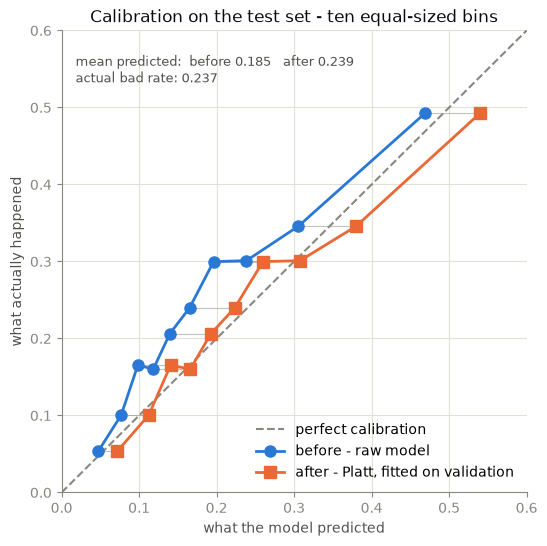

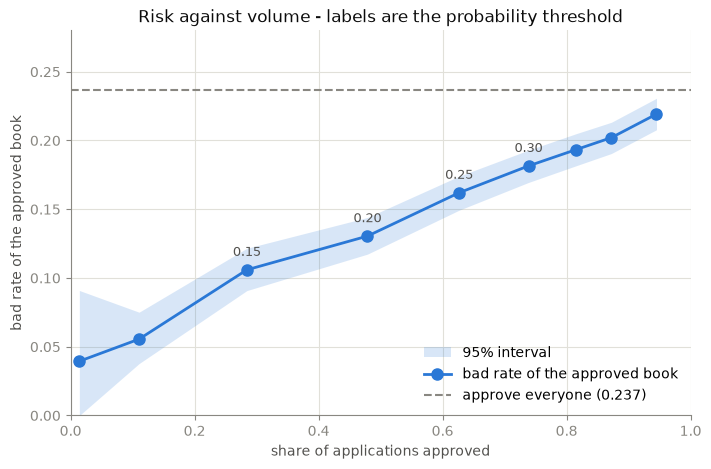

In [47]:
import matplotlib.pyplot as plt
from pathlib import Path

# ---- the palette --------------------------------------------------------
BLUE   = "#2a78d6"     # series 1
ORANGE = "#eb6834"     # series 2
GRID   = "#e1e0d9"
MUTED  = "#898781"     # axes, ticks, reference lines
SOFT   = "#52514e"     # secondary text
INK    = "#0b0b0b"     # titles
PAPER  = "#fcfcfb"     # saved background

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)


def style(ax):
    """push everything that isn't data into the background"""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)                      # grid behind the data
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED)


# ======================= figure A: calibration ===========================
cal_before = calibration_table(p_test,         y_test)
cal_after  = calibration_table(p_test_sigmoid, y_test)

fig, ax = plt.subplots(figsize=(6, 6))          # square - the diagonal must be 45 degrees
LIM = 0.6

ax.plot([0, LIM], [0, LIM], "--", color=MUTED, linewidth=1.5,
        label="perfect calibration", zorder=1)

# each bin holds the SAME loans before and after - a monotone map cannot
# reorder anything, so only the x moves. one connector per bin.
for xb, xa, yv in zip(cal_before["predicted"], cal_after["predicted"],
                      cal_after["actual"]):
    ax.plot([xb, xa], [yv, yv], color=MUTED, linewidth=0.8,
            alpha=0.5, zorder=2)

ax.plot(cal_before["predicted"], cal_before["actual"],
        color=BLUE, marker="o", markersize=8, linewidth=2,
        label="before - raw model", zorder=3)

ax.plot(cal_after["predicted"], cal_after["actual"],
        color=ORANGE, marker="s", markersize=8, linewidth=2,
        label="after - Platt, fitted on validation", zorder=3)

ax.set_xlim(0, LIM)
ax.set_ylim(0, LIM)                             # same range, or the diagonal lies
ax.set_xlabel("what the model predicted", color=SOFT)
ax.set_ylabel("what actually happened", color=SOFT)
ax.set_title("Calibration on the test set - ten equal-sized bins", color=INK)

ax.annotate(
    f"mean predicted:  before {p_test.mean():.3f}   after {p_test_sigmoid.mean():.3f}\n"
    f"actual bad rate: {y_test.mean():.3f}",
    xy=(0.03, 0.95), xycoords="axes fraction",
    fontsize=9, color=SOFT, va="top",
)

style(ax)
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG_DIR / "slice05_calibration.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()


# ==================== figure B: risk against volume ======================
x, y   = table["approved_share"], table["actual_bad"]
lo, hi = table["ci_low"], table["ci_high"]

fig, ax = plt.subplots(figsize=(8, 5))

# band first and underneath - alpha for a wash, linewidth 0 for no hard edge
ax.fill_between(x, lo, hi, color=BLUE, alpha=0.18, linewidth=0,
                label="95% interval", zorder=2)

ax.plot(x, y, color=BLUE, marker="o", markersize=8, linewidth=2,
        label="bad rate of the approved book", zorder=3)

ax.axhline(y_arr.mean(), linestyle="--", color=MUTED, linewidth=1.5,
           label=f"approve everyone ({y_arr.mean():.3f})", zorder=1)

# selective labels only - never a number on every point
for t in [0.15, 0.20, 0.25, 0.30]:
    r = table.loc[table["threshold"] == t].iloc[0]
    ax.annotate(f"{t:.2f}",
                xy=(r["approved_share"], r["actual_bad"]),
                xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9, color=SOFT)

ax.set_xlim(0, 1)
ax.set_ylim(0, 0.28)
ax.set_xlabel("share of applications approved", color=SOFT)
ax.set_ylabel("bad rate of the approved book", color=SOFT)
ax.set_title("Risk against volume - labels are the probability threshold", color=INK)

style(ax)
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG_DIR / "slice05_risk_vs_volume.png", dpi=150,
            bbox_inches="tight", facecolor=PAPER)
plt.show()

In [48]:
import joblib
import sklearn
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import date
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

MODEL_PATH = "../models/calibrated_logreg.joblib"
PRED_PATH  = "../data/processed/predictions_test_calibrated.parquet"

Path("../models").mkdir(exist_ok=True)


# ---- 1. the function that defines the order of the three pieces ---------
def predict_calibrated(bundle, X_raw):
    """Raw features in, honest probability out.

    scaler -> model -> calibrator, in that order. This function IS the
    definition of that order; slice 9 deploys it unchanged.
    """
    X = X_raw[bundle["columns"]]                 # saved order: the scaler works by position
    X_scaled = pd.DataFrame(                     # keep the names, or sklearn warns
        bundle["scaler"].transform(X),
        columns=bundle["columns"],
        index=X.index,
    )
    score = bundle["model"].decision_function(X_scaled)          # log-odds
    return bundle["calibrator"].predict_proba(score.reshape(-1, 1))[:, 1]


# ---- 2. the bundle -------------------------------------------------------
auc_point   = roc_auc_score(y_test, p_test_sigmoid)
brier_point = brier_score_loss(y_test, p_test_sigmoid)
ll_point    = log_loss(y_test, p_test_sigmoid)
auc_ci      = summary.loc[summary["metric"] == "AUC", ["ci_low", "ci_high"]].iloc[0].tolist()

bundle = {
    # the three fitted pieces
    "scaler":      scaler_inner,
    "model":       model_inner,
    "calibrator":  platt,
    "apply_order": ["scaler.transform",
                    "model.decision_function",
                    "calibrator.predict_proba[:, 1]"],

    "columns":         list(X_train_inner_s.columns),     # all 71 - the scaler needs them all
    "n_features_used": int((model_inner.coef_[0] != 0).sum()),

    "C":           0.05,
    "penalty":     "l1",
    "calibration": "sigmoid (Platt), fitted on validation log-odds",
    "split_date":  str(SPLIT_DATE.date()),

    "test_auc":      round(auc_point, 4),
    "test_auc_ci95": [round(v, 4) for v in auc_ci],
    "test_brier":    round(brier_point, 4),
    "test_log_loss": round(ll_point, 4),

    "trained_on":    f"features_train.parquet before {SPLIT_DATE.date()} "
                     f"({len(train_inner)} rows, 2013-01 to 2015-12)",
    "calibrated_on": f"rows from {SPLIT_DATE.date()} onward "
                     f"({len(valid)} rows, 2016-01 to 2016-08)",

    # found in slice 5, DOCUMENTED BUT NOT APPLIED - slice 9 applies it
    "loan_to_income_guard_not_applied": float(X_train_inner["loan_to_income"].max()),

    "sklearn_version": sklearn.__version__,
    "saved":           str(date.today()),
}

joblib.dump(bundle, MODEL_PATH)
print("saved:", MODEL_PATH)


# ---- 3. predictions for slice 7 -----------------------------------------
preds = test[["issue_d", "zip_code", "addr_state"]].copy().reset_index(drop=True)
preds["target"]               = y_test.values
preds["p_default_raw"]        = p_test          # before correction
preds["p_default_calibrated"] = p_test_sigmoid  # what a lender would actually use

preds.to_parquet(PRED_PATH, index=False)
print("saved:", PRED_PATH, preds.shape, "->", list(preds.columns))


# ---- 4. verify: load cold, rebuild from RAW features --------------------
loaded = joblib.load(MODEL_PATH)

print("\nbundle holds:", list(loaded.keys()))
print(f"  C={loaded['C']}  {loaded['n_features_used']} of {len(loaded['columns'])} features used")
print(f"  calibration:   {loaded['calibration']}")
print(f"  trained on     {loaded['trained_on']}")
print(f"  calibrated on  {loaded['calibrated_on']}")
print(f"  test AUC {loaded['test_auc']} CI {loaded['test_auc_ci95']}")
print(f"  saved {loaded['saved']} with sklearn {loaded['sklearn_version']}")

p_check = predict_calibrated(loaded, X_test)    # raw features - nothing pre-scaled

print(f"\nreloaded AUC:   {roc_auc_score(y_test, p_check):.4f}   (expected {loaded['test_auc']})")
print(f"max difference: {np.abs(p_check - p_test_sigmoid).max():.2e}")

# compare the ARRAYS, never a summary number - slice 4's stale-variable lesson
assert np.allclose(p_check, p_test_sigmoid), "the bundle does not reproduce the measured model"
print("verified: the file reproduces all 5,378 probabilities exactly")


# ---- 5. verify the predictions file -------------------------------------
back = pd.read_parquet(PRED_PATH)

assert (back["target"].values == y_test.values).all(),                  "target column scrambled"
assert np.allclose(back["p_default_calibrated"].values, p_test_sigmoid), "calibrated column differs"
assert np.allclose(back["p_default_raw"].values, p_test),                "raw column differs"
assert back["issue_d"].is_monotonic_increasing,                          "rows not in time order"

print(f"predictions file verified: {back.shape}, rows in time order")

saved: ../models/calibrated_logreg.joblib
saved: ../data/processed/predictions_test_calibrated.parquet (5378, 6) -> ['issue_d', 'zip_code', 'addr_state', 'target', 'p_default_raw', 'p_default_calibrated']

bundle holds: ['scaler', 'model', 'calibrator', 'apply_order', 'columns', 'n_features_used', 'C', 'penalty', 'calibration', 'split_date', 'test_auc', 'test_auc_ci95', 'test_brier', 'test_log_loss', 'trained_on', 'calibrated_on', 'loan_to_income_guard_not_applied', 'sklearn_version', 'saved']
  C=0.05  47 of 71 features used
  calibration:   sigmoid (Platt), fitted on validation log-odds
  trained on     features_train.parquet before 2016-01-01 (16134 rows, 2013-01 to 2015-12)
  calibrated on  rows from 2016-01-01 onward (4768 rows, 2016-01 to 2016-08)
  test AUC 0.6908 CI [0.6739, 0.7067]
  saved 2026-11-12 with sklearn 1.9.1

reloaded AUC:   0.6908   (expected 0.6908)
max difference: 0.00e+00
verified: the file reproduces all 5,378 probabilities exactly
predictions file verified: (5

In [49]:
lgb.__version__


NameError: name 'lgb' is not defined